# Predictive Maintenance Using Machine Learning

### Research Question

Can operational sensor measurements be used to predict industrial equipment failure?

### Dataset

This project uses the AI4I 2020 Predictive Maintenance Dataset from the UCI Machine Learning Repository.

The dataset contains 10,000 synthetic observations representing industrial machinery operating conditions.

The variables include:

- Air temperature (K)
- Process temperature (K)
- Rotational speed (rpm)
- Torque (Nm)
- Tool wear (min)
- Machine failure (target variable)

### Objectives

1. Assess dataset quality, including missing values and duplicates.
2. Investigate the distribution of machine failures.
3. Compare operating conditions between failed and non-failed observations.
4. Identify potential relationships between sensor measurements and machine failure.
5. Establish a foundation for subsequent machine learning experiments.

**Note:** The dataset is synthetic, so findings should not be interpreted as validated performance on real industrial equipment.

In [15]:
import sys
print(sys.version)

3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]


In [16]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("ai4i2020.csv")

print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [17]:

# Check missing values in each column
print("Missing values per column:")
print(df.isnull().sum())

# Check duplicate rows
print("\nNumber of duplicate rows:")
print(df.duplicated().sum())


Missing values per column:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Number of duplicate rows:
0


In [18]:
df.describe()


,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [19]:

# Count failures and non-failures
failure_counts = df["Machine failure"].value_counts()

print("Machine failure counts:")
print(failure_counts)

# Calculate percentage of failures
failure_rate = df["Machine failure"].mean() * 100

print(f"\nMachine failure rate: {failure_rate:.2f}%")


Machine failure counts:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Machine failure rate: 3.39%


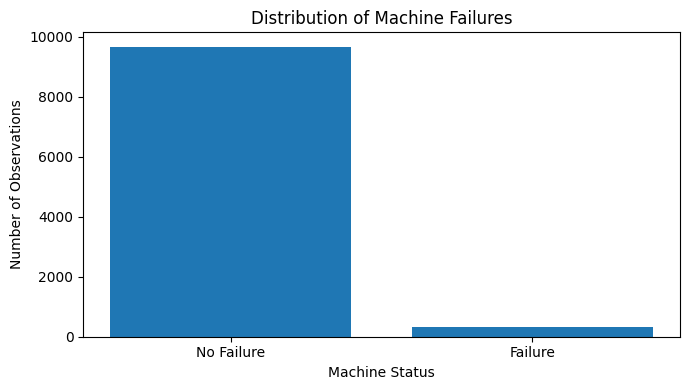

In [20]:

import matplotlib.pyplot as plt

failure_counts = (
    df["Machine failure"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(7, 4))

plt.bar(
    ["No Failure", "Failure"],
    failure_counts.values
)

plt.title("Distribution of Machine Failures")
plt.xlabel("Machine Status")
plt.ylabel("Number of Observations")

plt.tight_layout()
plt.show()


In [21]:

features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

group_means = df.groupby("Machine failure")[features].mean()

display(group_means.round(2))


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
Machine failure,,,,,
0,299.97,310.00,1540.26,39.63,106.69
1,300.89,310.29,1496.49,50.17,143.78


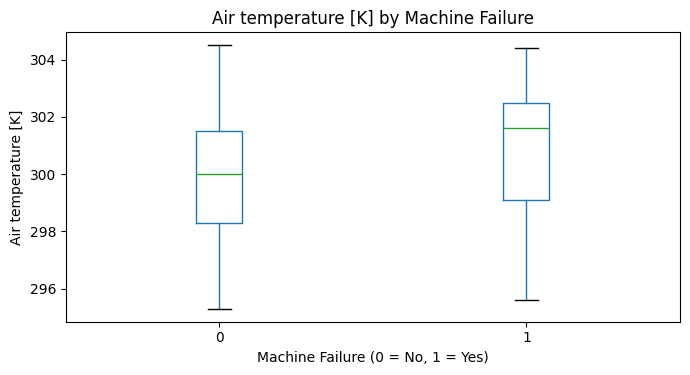

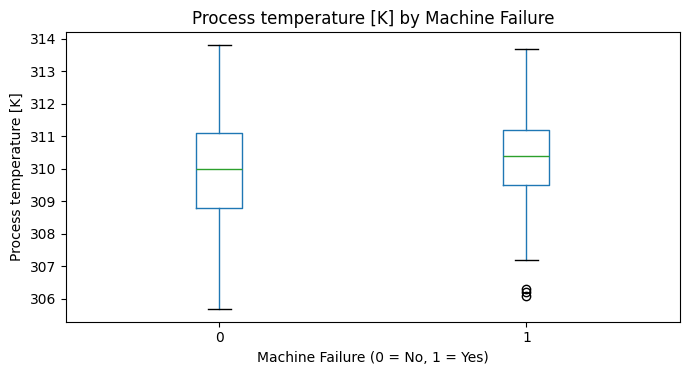

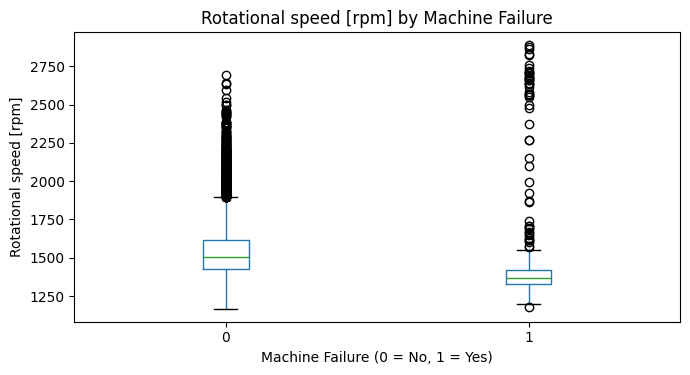

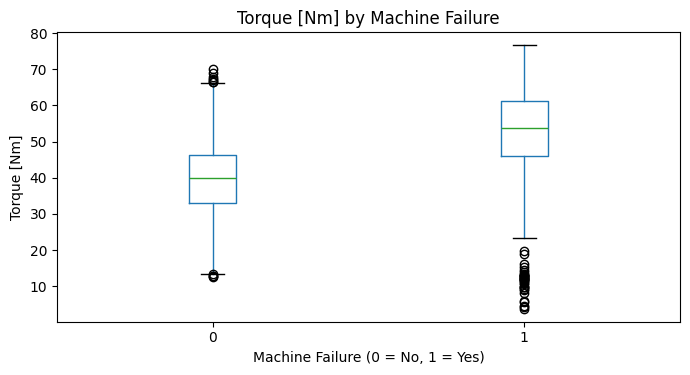

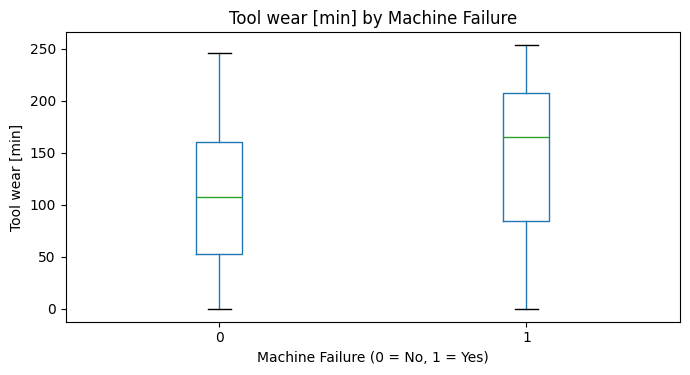

In [22]:

# Compare sensor measurements between
# failed and non-failed machines

for feature in features:

    fig, ax = plt.subplots(figsize=(7, 4))

    df.boxplot(
        column=feature,
        by="Machine failure",
        ax=ax,
        grid=False
    )

    ax.set_title(f"{feature} by Machine Failure")
    ax.set_xlabel("Machine Failure (0 = No, 1 = Yes)")
    ax.set_ylabel(feature)

    fig.suptitle("")
    plt.tight_layout()
    plt.show()


### Exploratory Data Analysis: Initial Findings

The dataset contains 10,000 observations, with a machine failure rate of 3.39%. No missing values were identified.

**Torque:** The average torque was 50.17 Nm for failed machines compared with 39.63 Nm for non-failed machines, representing an increase of approximately 26.6%. The boxplots also showed a higher median torque among failures.

**Tool Wear:** Failed machines had an average tool wear of 143.78 minutes compared with 106.69 minutes for non-failed machines, approximately 34.8% higher. This suggests a positive association between accumulated tool wear and machine failure.

**Rotational Speed:** The average rotational speed was lower in the failure group (1,496.49 rpm) than in the non-failure group (1,540.26 rpm). However, the failure distribution also contained several unusually high rotational-speed observations, suggesting a potentially nonlinear relationship.

**Temperature:** The failure group had slightly higher average air and process temperatures. The differences were smaller than those observed for torque and tool wear, although temperature may still contribute to failure prediction.

**Conclusion:** Torque and tool wear show particularly noticeable differences between the two groups. However, the distributions overlap, and the observed associations do not establish causation. Further analysis is required to investigate interactions between operating conditions and evaluate their predictive usefulness.

In [23]:

#five sensor measurements and failure target
features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

correlation_columns = features + ["Machine failure"]

#Pearson correlation coefficients
correlation_matrix = df[correlation_columns].corr()

display(correlation_matrix.round(3))


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
Air temperature [K],1.000,0.876,0.023,-0.014,0.014,0.083
Process temperature [K],0.876,1.000,0.019,-0.014,0.013,0.036
Rotational speed [rpm],0.023,0.019,1.000,-0.875,0.000,-0.044
Torque [Nm],-0.014,-0.014,-0.875,1.000,-0.003,0.191
Tool wear [min],0.014,0.013,0.000,-0.003,1.000,0.105
Machine failure,0.083,0.036,-0.044,0.191,0.105,1.000


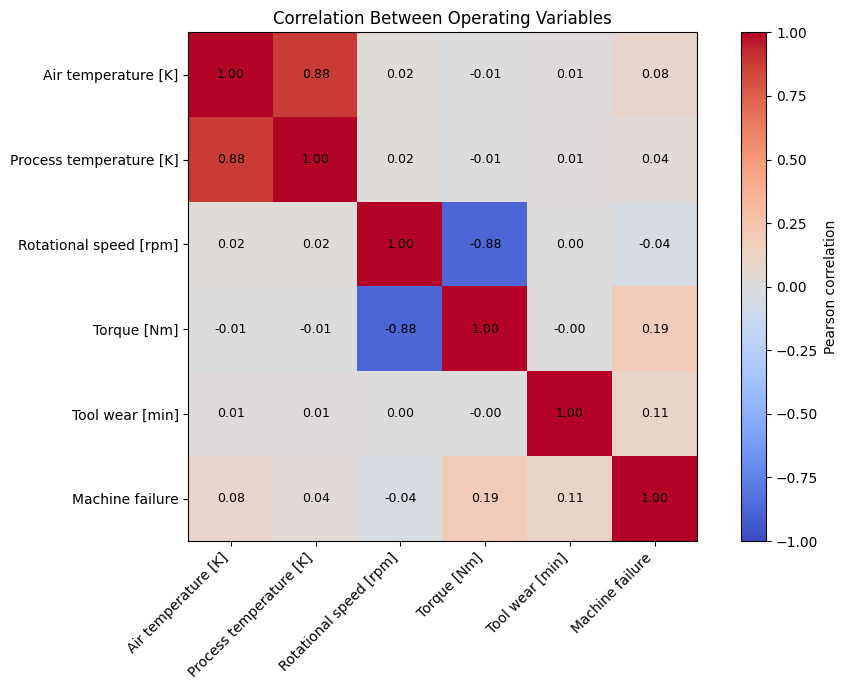

In [24]:

#Pearson correlations
fig, ax = plt.subplots(figsize=(10, 7))

im = ax.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(correlation_matrix.columns)))
ax.set_yticks(range(len(correlation_matrix.index)))

ax.set_xticklabels(
    correlation_matrix.columns,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(correlation_matrix.index)

for i in range(len(correlation_matrix.index)):
    for j in range(len(correlation_matrix.columns)):
        ax.text(
            j, i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=9
        )

fig.colorbar(im, ax=ax, label="Pearson correlation")
ax.set_title("Correlation Between Operating Variables")

plt.tight_layout()
plt.show()


In [25]:

#Rank by absolute correlation with failure

failure_correlations = (
    correlation_matrix["Machine failure"]
    .drop("Machine failure")
    .sort_values(key=abs, ascending=False)
)

print("Correlations with Machine Failure:")
display(failure_correlations.round(3))


Correlations with Machine Failure:


,Machine failure
Torque [Nm],0.191
Tool wear [min],0.105
Air temperature [K],0.083
Rotational speed [rpm],-0.044
Process temperature [K],0.036


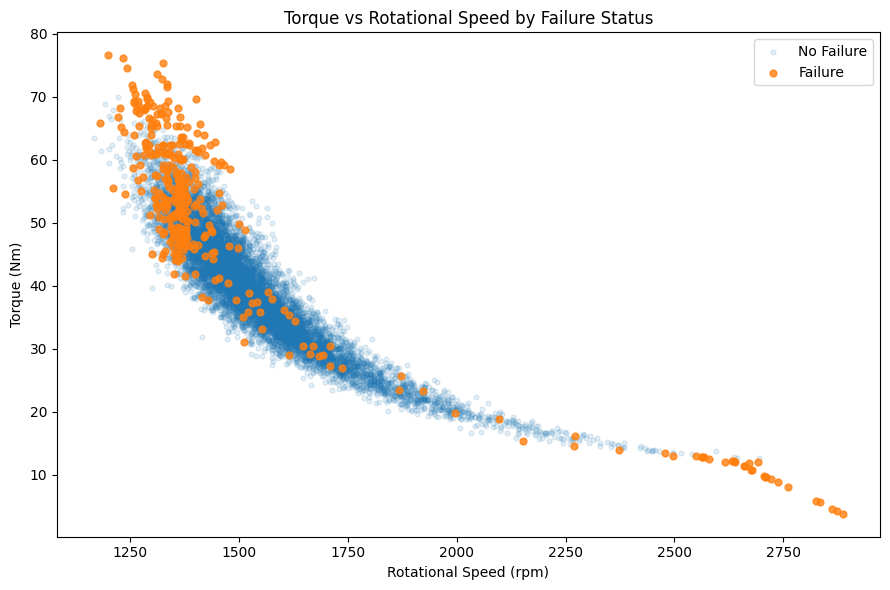

In [26]:

#torque and rotational speed by failure status

normal = df[df["Machine failure"] == 0]
failed = df[df["Machine failure"] == 1]

fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    normal["Rotational speed [rpm]"],
    normal["Torque [Nm]"],
    alpha=0.12,
    s=12,
    label="No Failure"
)

ax.scatter(
    failed["Rotational speed [rpm]"],
    failed["Torque [Nm]"],
    alpha=0.8,
    s=24,
    label="Failure"
)

ax.set_title("Torque vs Rotational Speed by Failure Status")
ax.set_xlabel("Rotational Speed (rpm)")
ax.set_ylabel("Torque (Nm)")
ax.legend()

plt.tight_layout()
plt.show()


**Correlation Analysis**

Pearson correlation analysis was conducted to investigate linear relationships between operating variables and machine failure.

Correlation with machine failure: Torque exhibited the strongest positive linear correlation with machine failure (r = 0.191), followed by tool wear (r = 0.105) and air temperature (r = 0.083). Rotational speed showed a weak negative correlation (r = -0.044), while process temperature had a very weak positive correlation (r = 0.036).

These results indicate that none of the individual operating measurements has a strong linear relationship with machine failure.

*Air and process temperatures:* A strong positive correlation (r = 0.876) was observed between air temperature and process temperature, indicating that higher ambient temperatures tend to coincide with higher process temperatures.

*Rotational speed and torque:* A strong negative correlation (r = -0.875) was identified, indicating that higher rotational speeds tend to coincide with lower torque values.

**Torque and Rotational Speed**

The scatter plot revealed a pronounced inverse relationship between torque and rotational speed.

Failure observations appeared concentrated in two regions: relatively low rotational speeds combined with high torque, and very high rotational speeds combined with low torque.

These patterns suggest that machine failure may be associated with particular combinations of operating conditions rather than individual measurements alone.

**Interpretation and Limitations**

The analysis identified potentially informative relationships between operating variables, but correlation does not establish causation.

Furthermore, Pearson correlation measures linear association and may not capture nonlinear relationships or interactions between variables.

The findings suggest that models capable of representing nonlinear relationships, such as random forests, may be useful for comparison with a logistic regression baseline.

The dataset is synthetic, so the findings should not be interpreted as validated relationships in real industrial equipment.